# 08 · Water and vegetation: what differs on the Kaggle images

The best model (`E08a` soup + AdaBN balanced, **71.69%**) is uncertain (confidence < 0.6) on about 15% of the
Kaggle images. Its top-2 pairs are SeaLake/Highway, SeaLake/Residential and the vegetation pairs
(AnnualCrop/PermanentCrop, Forest/HerbaceousVegetation, Pasture pairs). This notebook checks both groups
without labels.

**Questions**

1. Are the uncertain SeaLake images really water? (NDWI, image grids)
2. Was the earlier model (`E04` + AdaBN, 68.18%) also unsure about them?
3. How do the vegetation classes differ between EuroSAT and Kaggle (NDVI, bare soil, moisture, texture)?
4. Do the cues that separate the confusable pairs in EuroSAT survive on Kaggle?

**Measures per image**

| Measure | Formula | Meaning |
|---|---|---|
| water pixels | share of pixels with NDWI = (B03 − B08) / (B03 + B08) > 0 | water reflects green, absorbs NIR |
| NDVI | (B08 − B04) / (B08 + B04), mean over pixels | green vegetation |
| bare pixels | share of pixels with NDVI < 0.3 | soil, harvested/ploughed fields |
| NDVI pixel std | std of NDVI within the image | stripes, mixed fields |
| red-edge index | (B07 − B05) / (B07 + B05) | chlorophyll / vigour |
| NDMI | (B08 − B11) / (B08 + B11) | water content of vegetation |
| NIR edges | mean absolute neighbour difference of B08 / mean B08 | texture, sharpness |

**Kaggle classes are the soup's predictions**, not labels: the Kaggle numbers describe what the model *calls*
a class. EuroSAT images are compared raw and after `hist_split` (what the model is trained on).


## 1 · Setup and data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, band_index, load_test, load_train
from src.experiment import find_run, load_correction
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.training import load_run, predict_views, to_device_images
from src.utils import get_device

apply_style()
device = get_device()

# ---- Settings --------------------------------------------------------------------------
MAIN_RUN = "adabn_balanced_soup_e09_e10_effb0"                 # E08a soup + AdaBN, 71.69%
OLD_RUN = "adabn_balanced_contrast_aug_hist_split_effb0"       # E04 + AdaBN, 68.18% (used in 06)
SOUP_MEMBERS = {"E06b": "adabn_balanced_pseudo_label_r2_contrast_aug_hist_split_effb0",
                "E06c": "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"}
LOW_CONF, HIGH_CONF = 0.6, 0.8
VEG = ["AnnualCrop", "PermanentCrop", "Pasture", "HerbaceousVegetation", "Forest"]
N_EUROSAT = 600                                                # EuroSAT images per class
SEED = 0

X_all, meta = load_train()
X_kg, test_ids = load_test()
X_kg = np.asarray(X_kg)
kg_images = to_device_images(X_kg, device)
print(f"Kaggle {len(X_kg):,} images, EuroSAT {len(X_all):,} images")

Kaggle 4,232 images, EuroSAT 27,000 images


## 2 · Predictions of the soup (and of E04 for comparison)

In [2]:
def views_of(name_suffix):
    run_dir = find_run(name_suffix)
    model, normalizer, _ = load_run(run_dir, device)
    print("loaded", run_dir.relative_to(PROJECT_ROOT))
    return predict_views(model, kg_images, normalizer)


prob = views_of(MAIN_RUN).mean(0)
old_prob = views_of(OLD_RUN).mean(0)
order = np.argsort(-prob, axis=1)
kg = pd.DataFrame({"test_id": test_ids["test_id"].values,
                   "pred": np.array(CLASSES)[order[:, 0]], "second": np.array(CLASSES)[order[:, 1]],
                   "conf": prob.max(1), "old_pred": np.array(CLASSES)[old_prob.argmax(1)],
                   "old_conf": old_prob.max(1)})
low = kg[kg["conf"] < LOW_CONF]
pair = low.apply(lambda r: " / ".join(sorted([r["pred"], r["second"]])), axis=1)
print(f"Uncertain (conf < {LOW_CONF}): {len(low):,} of {len(kg):,} ({len(low) / len(kg):.1%})")
pair.value_counts().head(10).to_frame("uncertain images")

loaded runs/2026-10-13_1843_adabn_balanced_soup_e09_e10_effb0


loaded runs/2026-10-12_1040_adabn_balanced_contrast_aug_hist_split_effb0


Uncertain (conf < 0.6): 627 of 4,232 (14.8%)


,uncertain images
Highway / SeaLake,118
Residential / SeaLake,76
AnnualCrop / PermanentCrop,63
Forest / HerbaceousVegetation,55
Pasture / PermanentCrop,29
HerbaceousVegetation / Pasture,22
AnnualCrop / Pasture,22
Industrial / Residential,20
AnnualCrop / Highway,14
Highway / PermanentCrop,14


## 3 · Water: are the uncertain SeaLake images water?

NDWI > 0 marks water pixels without any model. If the uncertain SeaLake images are almost all water pixels,
the model's top choice is right and only its confidence is low.

In [3]:
def band(X, name):
    return X[:, band_index(name)].astype(np.float32)


g, nir = band(X_kg, "B03"), band(X_kg, "B08")
kg["water_px"] = ((g - nir) / (g + nir + 1e-6) > 0).mean(axis=(1, 2))
del g, nir

is_pair = lambda a, b: (kg["conf"] < LOW_CONF) & kg[["pred", "second"]].isin([a, b]).all(axis=1)
groups = {
    "SeaLake, conf ≥ 0.9": (kg["pred"] == "SeaLake") & (kg["conf"] >= 0.9),
    "SeaLake, 0.6–0.9": (kg["pred"] == "SeaLake") & kg["conf"].between(LOW_CONF, 0.9),
    "uncertain SeaLake/Highway": is_pair("SeaLake", "Highway"),
    "uncertain SeaLake/Residential": is_pair("SeaLake", "Residential"),
    "Residential, conf ≥ 0.9": (kg["pred"] == "Residential") & (kg["conf"] >= 0.9),
}
pd.DataFrame({name: {"images": int(m.sum()), "median water pixels": kg.loc[m, "water_px"].median(),
                     "> 50% water pixels": (kg.loc[m, "water_px"] > 0.5).mean(),
                     "predicted SeaLake": (kg.loc[m, "pred"] == "SeaLake").mean(),
                     "E04: predicted SeaLake": (kg.loc[m, "old_pred"] == "SeaLake").mean(),
                     "E04: mean confidence": kg.loc[m, "old_conf"].mean(),
                     "soup: mean confidence": kg.loc[m, "conf"].mean()}
              for name, m in groups.items()}).T.round(3)

,images,median water pixels,> 50% water pixels,predicted SeaLake,E04: predicted SeaLake,E04: mean confidence,soup: mean confidence
"SeaLake, conf ≥ 0.9",19.0,0.889,1.000,1.0,1.0,0.880,0.928
"SeaLake, 0.6–0.9",801.0,0.998,0.998,1.0,1.0,0.896,0.760
uncertain SeaLake/Highway,118.0,1.000,1.000,1.0,1.0,0.862,0.441
uncertain SeaLake/Residential,76.0,1.000,1.000,1.0,1.0,0.873,0.525
"Residential, conf ≥ 0.9",295.0,0.003,0.000,0.0,0.0,0.822,0.932


E04 was confident on these images. Is the drop caused by the pseudo-label rounds or by the soup?
Same images, each soup member on its own (with AdaBN) vs the soup.

In [4]:
open_water = (kg["pred"] == "SeaLake") & (kg["water_px"] > 0.95)
uncertain_water = (kg["pred"] == "SeaLake") & (kg["conf"] < LOW_CONF)
member_conf = {"E04": old_prob.max(1)} | {k: views_of(v).mean(0).max(1) for k, v in SOUP_MEMBERS.items()}
member_conf["soup (E08a)"] = kg["conf"].values
pd.DataFrame({k: {"open water (> 95% water pixels)": c[open_water].mean(),
                  "water the soup is unsure about": c[uncertain_water].mean(), "all Kaggle images": c.mean()}
              for k, c in member_conf.items()}).T.round(3).rename_axis("mean confidence")

loaded runs/2026-10-12_1555_adabn_balanced_pseudo_label_r2_contrast_aug_hist_split_effb0


loaded runs/2026-10-12_1626_adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0


,open water (> 95% water pixels),water the soup is unsure about,all Kaggle images
mean confidence,,,
E04,0.892,0.865,0.736
E06b,0.891,0.882,0.814
E06c,0.873,0.871,0.816
soup (E08a),0.703,0.476,0.774


Top row true colour, bottom row false colour (B08/B04/B03: vegetation red, water black). A **fixed**
stretch for all images, so dark stays dark.

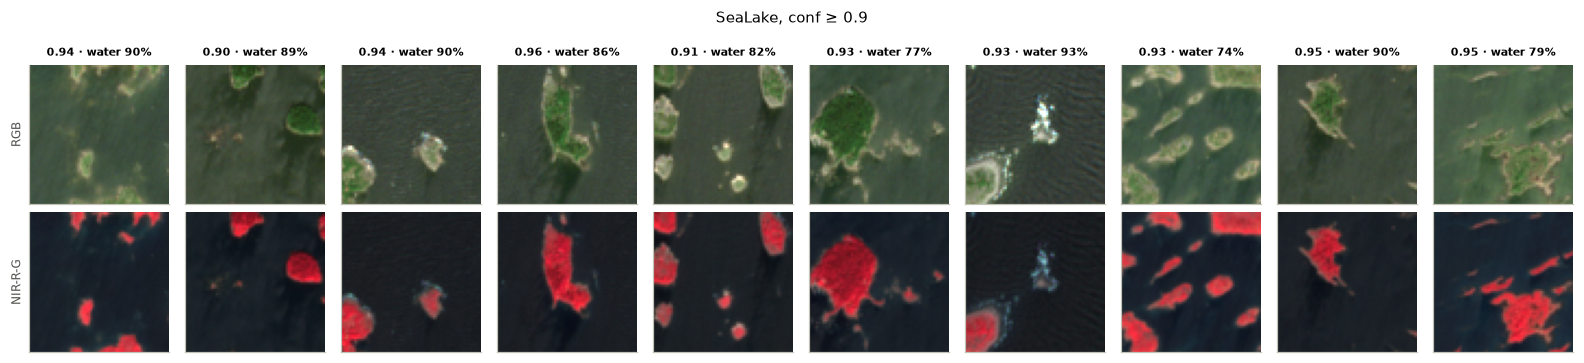

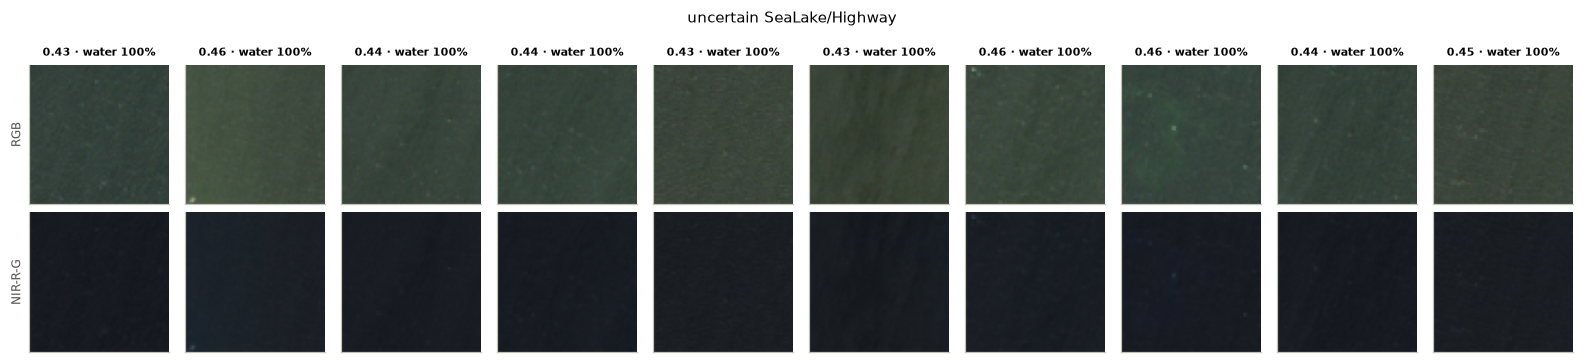

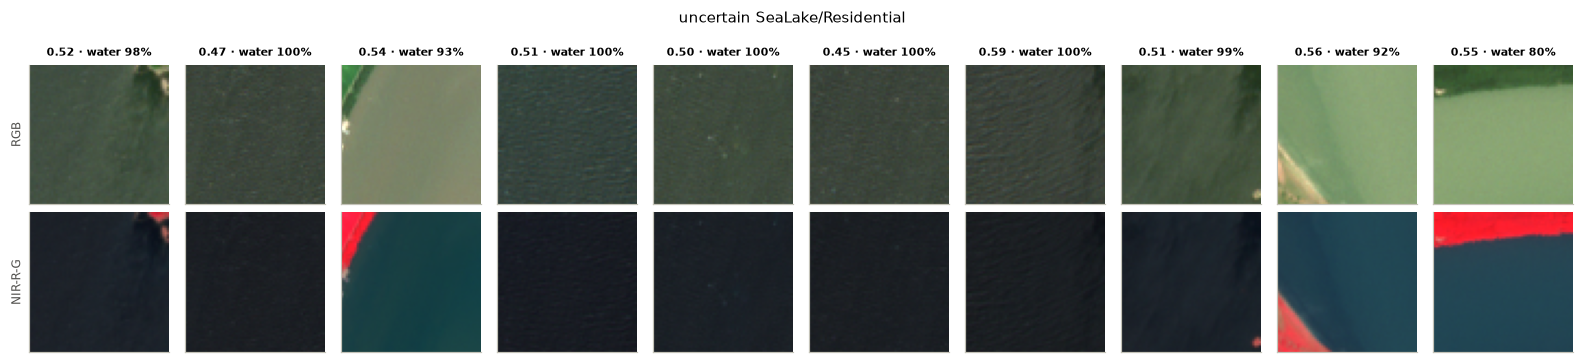

In [5]:
rng = np.random.default_rng(SEED)


def show_grid(X, idx, titles, suptitle, n=10):
    fig, axes = plt.subplots(2, n, figsize=(n * 1.45, 3.4))
    for k in range(n):
        for r, (bands, scale) in enumerate([(["B04", "B03", "B02"], 1500), (["B08", "B04", "B03"], 3500)]):
            ax = axes[r, k]
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if k >= len(idx):
                ax.axis("off"); continue
            img = np.stack([X[idx[k], band_index(b)] for b in bands], -1).astype(np.float32)
            ax.imshow(np.clip(img / scale, 0, 1) ** 0.8)
            if r == 0:
                ax.set_title(titles[k], fontsize=7)
    axes[0, 0].set_ylabel("RGB", fontsize=8); axes[1, 0].set_ylabel("NIR-R-G", fontsize=8)
    fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()


for name in ["SeaLake, conf ≥ 0.9", "uncertain SeaLake/Highway", "uncertain SeaLake/Residential"]:
    idx = rng.choice(np.flatnonzero(groups[name]), min(10, groups[name].sum()), replace=False)
    show_grid(X_kg, idx, [f"{kg['conf'][i]:.2f} · water {kg['water_px'][i]:.0%}" for i in idx], name)

## 4 · Vegetation: EuroSAT vs Kaggle per class

`N_EUROSAT` random EuroSAT images per vegetation class, raw and after `hist_split`, against the Kaggle images
the soup puts in that class (confident ≥ 0.8 and uncertain < 0.6 separately). Medians per group.

In [6]:
def features(X):
    X = X.astype(np.float32)
    b = lambda name: X[:, band_index(name)]
    ratio = lambda a, c: (a - c) / (a + c + 1e-6)
    ndvi = ratio(b("B08"), b("B04"))
    nir = b("B08")
    edges = np.abs(np.diff(nir, axis=2)).mean((1, 2)) + np.abs(np.diff(nir, axis=1)).mean((1, 2))
    return pd.DataFrame({
        "NDVI": ndvi.mean((1, 2)), "NDVI pixel std": ndvi.std((1, 2)), "bare pixels": (ndvi < 0.3).mean((1, 2)),
        "red-edge index": ratio(b("B07"), b("B05")).mean((1, 2)), "NDMI": ratio(b("B08"), b("B11")).mean((1, 2)),
        "red (B04)": b("B04").mean((1, 2)), "NIR (B08)": nir.mean((1, 2)), "SWIR (B11)": b("B11").mean((1, 2)),
        "NIR edges": edges / (nir.mean((1, 2)) + 1e-6),
    })


labels = meta["label"].values
eu_idx = np.sort(np.concatenate([rng.choice(np.flatnonzero(labels == c), N_EUROSAT, replace=False) for c in VEG]))
X_eu = np.asarray(X_all[eu_idx])
F_raw = features(X_eu).assign(cls=labels[eu_idx])
F_hs = features(load_correction("hist_split")(X_eu)).assign(cls=labels[eu_idx])
F_kg = features(X_kg).assign(cls=kg["pred"].values, conf=kg["conf"].values)

sets = {"EuroSAT raw": lambda c: F_raw[F_raw["cls"] == c],
        "EuroSAT hist_split": lambda c: F_hs[F_hs["cls"] == c],
        f"Kaggle conf ≥ {HIGH_CONF}": lambda c: F_kg[(F_kg["cls"] == c) & (F_kg["conf"] >= HIGH_CONF)],
        f"Kaggle conf < {LOW_CONF}": lambda c: F_kg[(F_kg["cls"] == c) & (F_kg["conf"] < LOW_CONF)]}
rows = {}
for c in VEG:
    for name, get in sets.items():
        d = get(c)
        rows[(c, name)] = d.drop(columns=[k for k in ("cls", "conf") if k in d]).median().to_dict() | {"n": len(d)}
veg_table = pd.DataFrame(rows).T
veg_table.round(3)

NDVI  NDVI pixel std  bare pixels  \
AnnualCrop           EuroSAT raw         0.344           0.177        0.592   
                     EuroSAT hist_split  0.501           0.190        0.177   
                     Kaggle conf ≥ 0.8   0.663           0.205        0.077   
                     Kaggle conf < 0.6   0.682           0.192        0.048   
PermanentCrop        EuroSAT raw         0.353           0.107        0.346   
                     EuroSAT hist_split  0.540           0.119        0.051   
                     Kaggle conf ≥ 0.8   0.649           0.202        0.068   
                     Kaggle conf < 0.6   0.677           0.187        0.052   
Pasture              EuroSAT raw         0.668           0.100        0.007   
                     EuroSAT hist_split  0.835           0.071        0.000   
                     Kaggle conf ≥ 0.8   0.777           0.141        0.011   
                     Kaggle conf < 0.6   0.731           0.162        0.020   
HerbaceousVegetation EuroSAT raw         0.361           0.066        0.237   
                     EuroSAT hist_split  0.599           0.077        0.001   
                     Kaggle conf ≥ 0.8   0.710           0.096        0.000   
                     Kaggle conf < 0.6   0.734           0.121        0.003   
Forest               EuroSAT raw         0.715           0.042        0.000   
                     EuroSAT hist_split  0.872           0.024        0.000   
                     Kaggle conf ≥ 0.8   0.812           0.057        0.000   
                     Kaggle conf < 0.6   0.761           0.106        0.001   

                                         red-edge index   NDMI  red (B04)  \
AnnualCrop           EuroSAT raw                  0.269  0.053   1435.908   
                     EuroSAT hist_split           0.316  0.133   1088.179   
                     Kaggle conf ≥ 0.8            0.450  0.266    696.428   
                     Kaggle conf < 0.6            0.471  0.272    575.006   
PermanentCrop        EuroSAT raw                  0.275  0.012   1283.892   
                     EuroSAT hist_split           0.333  0.088    909.332   
                     Kaggle conf ≥ 0.8            0.437  0.238    726.598   
                     Kaggle conf < 0.6            0.436  0.241    615.491   
Pasture              EuroSAT raw                  0.480  0.271    633.828   
                     EuroSAT hist_split           0.564  0.373    319.305   
                     Kaggle conf ≥ 0.8            0.528  0.302    438.398   
                     Kaggle conf < 0.6            0.476  0.273    478.183   
HerbaceousVegetation EuroSAT raw                  0.248 -0.006   1000.750   
                     EuroSAT hist_split           0.304  0.064    611.611   
                     Kaggle conf ≥ 0.8            0.404  0.228    371.707   
                     Kaggle conf < 0.6            0.428  0.248    342.551   
Forest               EuroSAT raw                  0.573  0.338    408.977   
                     EuroSAT hist_split           0.627  0.423    189.077   
                     Kaggle conf ≥ 0.8            0.544  0.358    243.884   
                     Kaggle conf < 0.6            0.450  0.306    294.304   

                                         NIR (B08)  SWIR (B11)  NIR edges  \
AnnualCrop           EuroSAT raw          3051.631    2678.096      0.052   
                     EuroSAT hist_split   3490.463    2597.224      0.058   
                     Kaggle conf ≥ 0.8    3723.935    2118.679      0.101   
                     Kaggle conf < 0.6    3589.594    1909.005      0.122   
PermanentCrop        EuroSAT raw          2785.218    2690.862      0.081   
                     EuroSAT hist_split   3141.243    2584.330      0.101   
                     Kaggle conf ≥ 0.8    3586.150    2169.424      0.120   
                     Kaggle conf < 0.6    3488.674    2006.906      0.128   
Pasture              EuroSAT raw          3369.794    1950.408      0.1

Distributions of the three measures that differ most: EuroSAT after `hist_split` (what the model is trained on)
vs Kaggle (all images the soup puts in the class).

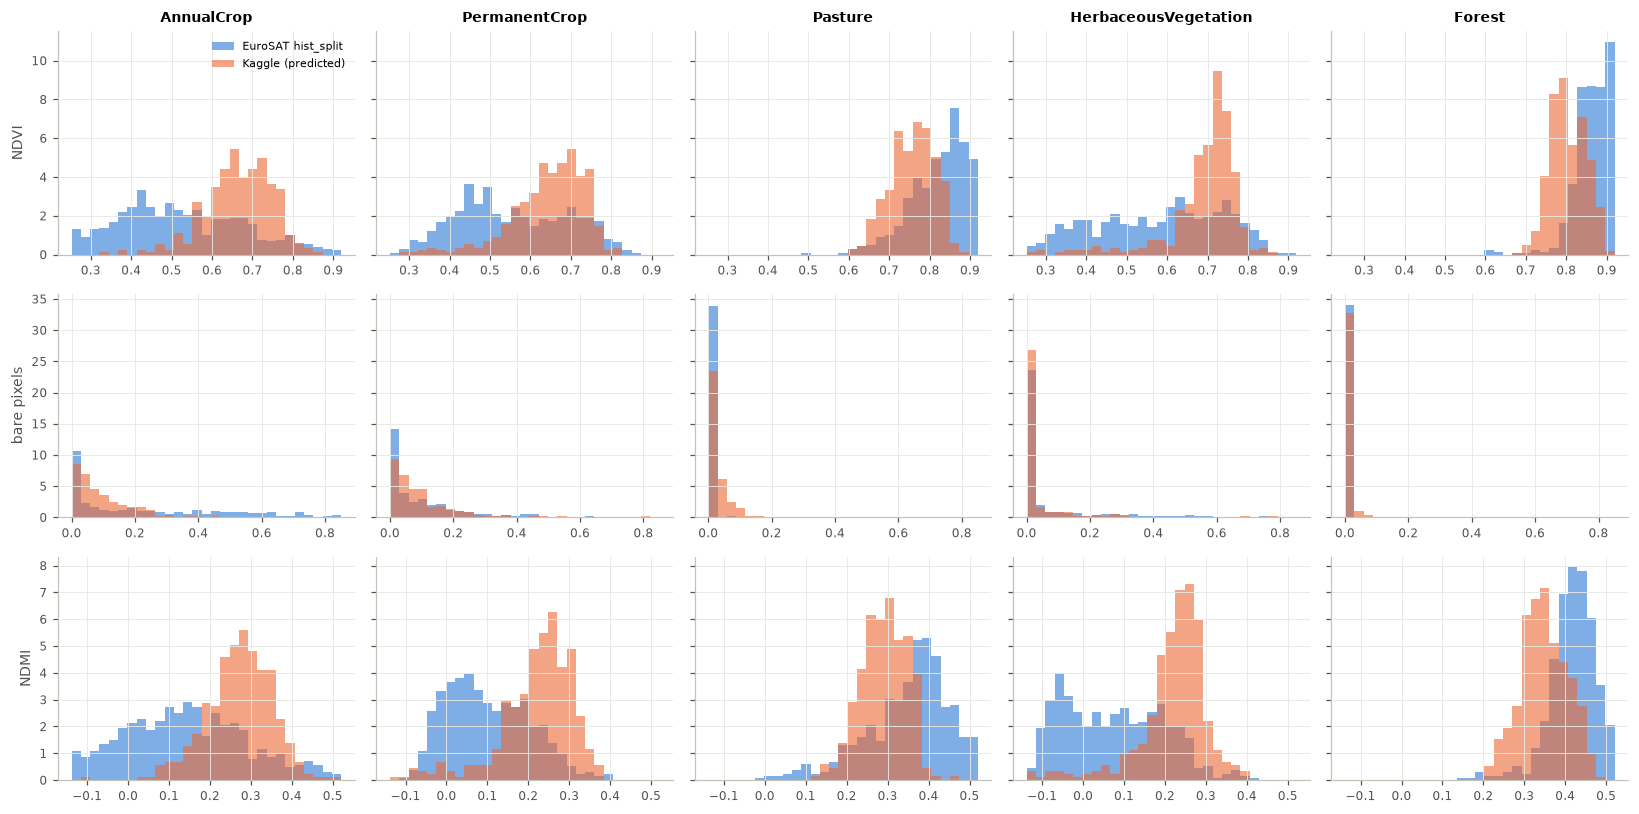

In [7]:
cols = ["NDVI", "bare pixels", "NDMI"]
fig, axes = plt.subplots(len(cols), len(VEG), figsize=(15, 7.5), sharey="row")
for r, col in enumerate(cols):
    lo, hi = np.percentile(np.r_[F_hs[col], F_kg[col][np.isin(F_kg["cls"], VEG)]], [1, 99])
    bins = np.linspace(lo, hi, 30)
    for k, c in enumerate(VEG):
        ax = axes[r, k]
        ax.hist(F_hs.loc[F_hs["cls"] == c, col], bins, density=True, alpha=0.6, color=TRAIN_COLOR, label="EuroSAT hist_split")
        ax.hist(F_kg.loc[F_kg["cls"] == c, col], bins, density=True, alpha=0.6, color=TEST_COLOR, label="Kaggle (predicted)")
        if r == 0:
            ax.set_title(c, fontsize=9)
        if k == 0:
            ax.set_ylabel(col)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### Crops in both datasets

Random EuroSAT AnnualCrop / PermanentCrop images (after `hist_split`) next to Kaggle images the soup calls
AnnualCrop / PermanentCrop. Titles: NDVI and share of bare pixels.

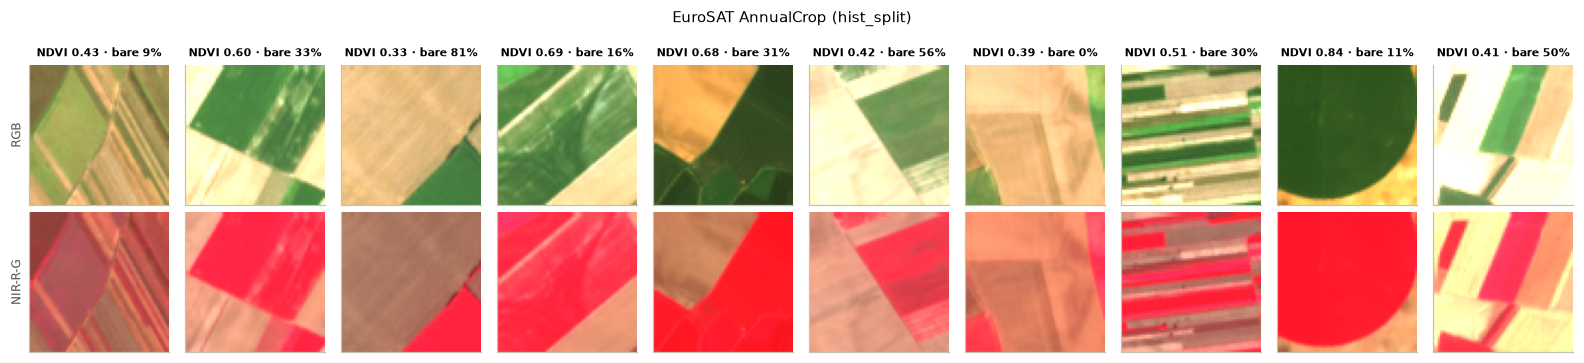

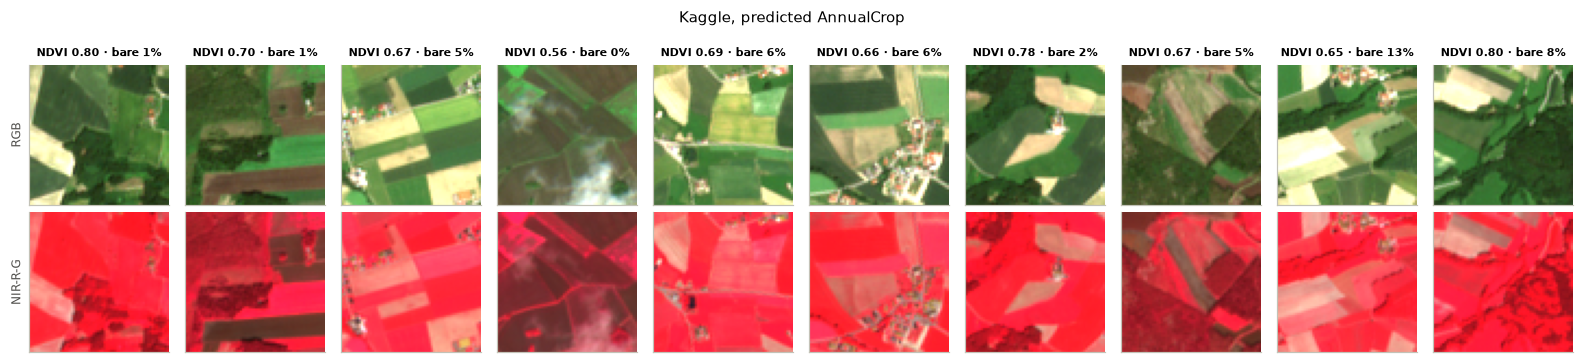

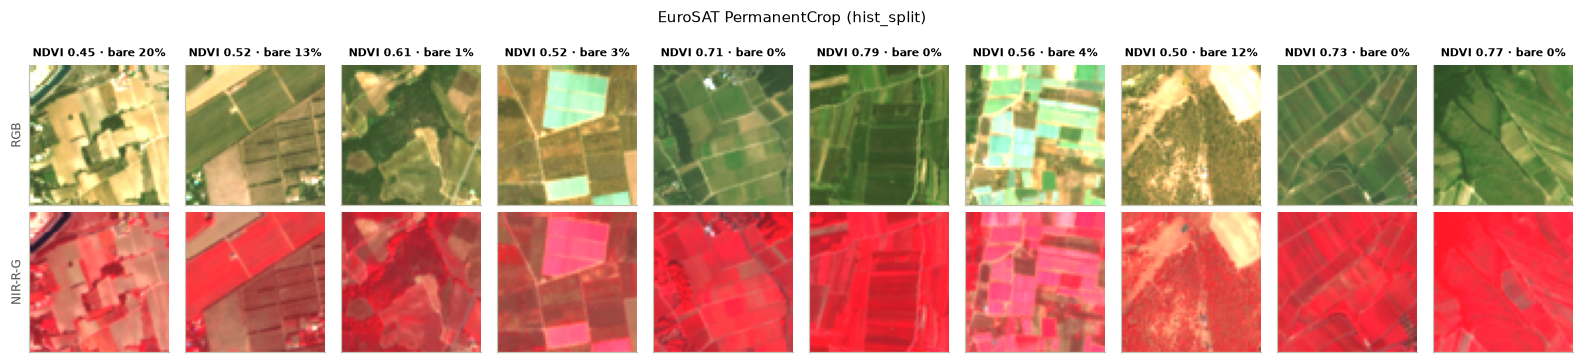

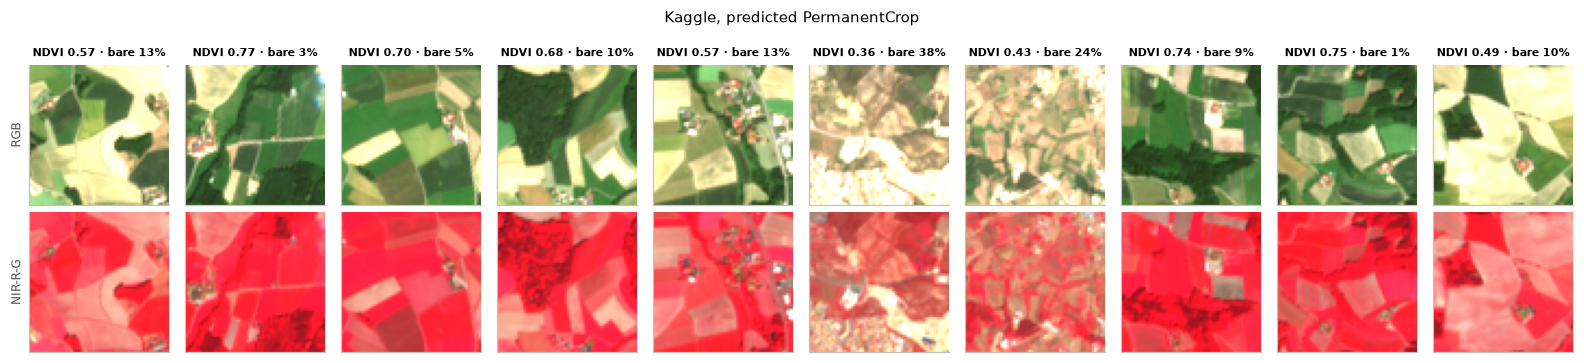

In [8]:
X_eu_hs = load_correction("hist_split")(X_eu)
for c in ["AnnualCrop", "PermanentCrop"]:
    idx = rng.choice(np.flatnonzero(labels[eu_idx] == c), 10, replace=False)
    show_grid(X_eu_hs, idx, [f"NDVI {F_hs['NDVI'][i]:.2f} · bare {F_hs['bare pixels'][i]:.0%}" for i in idx],
              f"EuroSAT {c} (hist_split)")
    idx = rng.choice(np.flatnonzero(kg["pred"] == c), 10, replace=False)
    show_grid(X_kg, idx, [f"NDVI {F_kg['NDVI'][i]:.2f} · bare {F_kg['bare pixels'][i]:.0%}" for i in idx],
              f"Kaggle, predicted {c}")

## 5 · Do the cues that separate the confusable pairs survive?

Separation of two classes on one measure: |difference of medians| / mean interquartile range (0 = same,
> 1 = clearly apart). On Kaggle this uses the soup's confident predictions (≥ 0.8), so it is partly circular:
it shows on which cues the model's own classes still differ.

In [9]:
def separation(F, a, b, col):
    A, B = F.loc[F["cls"] == a, col], F.loc[F["cls"] == b, col]
    iqr = ((A.quantile(.75) - A.quantile(.25)) + (B.quantile(.75) - B.quantile(.25))) / 2
    return abs(A.median() - B.median()) / (iqr + 1e-9)


PAIRS = [("AnnualCrop", "PermanentCrop"), ("Forest", "HerbaceousVegetation"),
         ("Pasture", "PermanentCrop"), ("HerbaceousVegetation", "Pasture"), ("AnnualCrop", "Pasture")]
SEP_COLS = ["NDVI", "NDVI pixel std", "bare pixels", "red-edge index", "NDMI", "NIR edges"]
F_kg_conf = F_kg[F_kg["conf"] >= HIGH_CONF]
sep = pd.DataFrame({(f"{a} / {b}", name): {col: separation(F, a, b, col) for col in SEP_COLS}
                    for a, b in PAIRS for name, F in [("EuroSAT", F_hs), ("Kaggle", F_kg_conf)]}).T
sep.round(2).style.background_gradient(cmap="Greens", vmin=0, vmax=2).format("{:.2f}")

## 6 · Save the measures

In [10]:
out = PROJECT_ROOT / "artifacts" / "kaggle_water_vegetation.csv"
table = kg.join(F_kg.drop(columns=["cls", "conf"]))
table.round(4).to_csv(out, index=False)
print("Saved", out.relative_to(PROJECT_ROOT), table.shape)

Saved artifacts/kaggle_water_vegetation.csv (4232, 16)


## 7 · Conclusion

**Water**

- **The uncertain SeaLake images are water.** All 194 SeaLake/Highway and SeaLake/Residential images are almost
  entirely water pixels (NDWI), and the soup's top class is SeaLake for every one of them; the grids show plain,
  turbid open water. These are almost certainly correct predictions.
- **The low confidence is a soup artefact.** Each soup member (E06b, E06c) is about 0.88 confident on the same images,
  E04 0.86–0.90; averaging their weights drops it to 0.44–0.53. (The pseudo-labels are not the cause: about 95% of the
  SeaLake pseudo-labels in rounds 1 and 2 were open water.)
- **Consequence:** don't select pseudo-labels by the soup's confidence; use the members (or agreement between them).

**Vegetation**

- **EuroSAT crops are largely bare soil, Kaggle crops are green.** AnnualCrop: 59% bare pixels (NDVI < 0.3) raw,
  18% after `hist_split`, 5–8% on Kaggle; NDVI 0.50 vs 0.66–0.68. PermanentCrop and HerbaceousVegetation are also
  greener on Kaggle (NDVI +0.11 to +0.13). Kaggle looks like a different season (growing season) and, in part, like
  L2A data, whose NDVI is higher; histogram matching per band closes only part of the gap.
- **Kaggle vegetation is wetter:** NDMI 0.23–0.36 against 0.06–0.42 in EuroSAT, the biggest gain for the crops and
  HerbaceousVegetation (+0.13 to +0.16). SWIR is lower in every class except Pasture.
- **The vegetation classes move closer together.** NDVI medians span 0.50–0.87 in EuroSAT and 0.65–0.81 on Kaggle:
  crops and HerbaceousVegetation get greener, Forest and Pasture less green and less uniform (Forest NDVI pixel std
  0.024 → 0.057).
- **AnnualCrop vs PermanentCrop loses its EuroSAT cues.** In EuroSAT the two differ in NDVI pixel std (separation
  0.91) and NIR texture (1.49): stripes of bare soil vs regular plantations. Among the soup's confident Kaggle
  predictions the same measures separate them at 0.07 and 0.43; both look like uniform green fields. Forest vs
  HerbaceousVegetation stays separable (NDVI, red-edge, NDMI all > 1.4), but less than in EuroSAT.
- Kaggle images have sharper texture in every class (NIR edges), consistent with the higher contrast found in
  `04_haze_correction`.

**What this means for the experiments**

- The missing piece is **green-season crop fields with labels**. Spectral corrections and contrast augmentation can't
  create them; pseudo-labelled Kaggle images are the only source.
- The Kaggle numbers above use the soup's own predictions as classes, so the pair separations are partly circular. The
  bare-soil and NDVI shifts hold for every vegetation class and do not depend on that.
- Measures per Kaggle image saved to `artifacts/kaggle_water_vegetation.csv`.


**Correction (2026-10-25, `09_label_convention`):** NDWI undercounts water on the Kaggle images. The haze removal lowers
B03 so much that dark water often has NDWI < 0 (23% of the images predicted River look dry). The `water_px` column of
`artifacts/kaggle_water_vegetation.csv` is therefore too low for rivers; `09` uses NIR (B08) < 800 instead. The
SeaLake findings above are unaffected (open water stays above NDWI 0).